<span style="font-size:24pt; color:blue; font-family: 'Times New Roman'">Notebook:: 
    <span style="color:green;"> To Preprocess the FACTS-FAIR input to include SRCities scenarios. </span>
</span>
<br>
<span style="font-size:12pt; color:black; font-family:Georgia, serif;font-style:italic">by Praveen Kumar & Kelly McCusker </span>
<br>

In [1]:
import numpy as np
import h5py
import xarray as xr
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from datetime import datetime

### ~~THis is new data sent over by Sophie, downloaded on 09/24 ish~~
### THis is new data sent over by Zebdee, downloaded on 09/30 ish

In [2]:
# datanc=xr.open_dataset("_data/006_for-ipcc-cities-slr-emulators.nc")
datanc=xr.open_dataset("_data/007_for-ipcc-cities-slr-emulators.nc")
# print(datanc)
datanc

<xarray.Dataset> Size: 381MB
Dimensions:                         (run_id: 600, plotting_label: 16,
                                     year: 551, unit: 2, component: 2)
Coordinates:
  * run_id                          (run_id) int64 5kB 0 1 2 3 ... 597 598 599
  * plotting_label                  (plotting_label) <U8 512B 'SSP1-1.9' ... ...
  * year                            (year) int64 4kB 1750 1751 ... 2299 2300
  * unit                            (unit) <U5 40B 'W/m^2' 'ZJ'
  * component                       (component) <U5 40B 'Ocean' 'Other'
Data variables:
    Surface Air Temperature Change  (run_id, plotting_label, year) float64 42MB ...
    Heat Content                    (run_id, unit, plotting_label, component, year) float64 169MB ...
    Heat Uptake                     (run_id, unit, plotting_label, component, year) float64 169MB ...

In [3]:
gsat_median = (
    datanc["Surface Air Temperature Change"]
    .sel(plotting_label="H")
    .median(dim="run_id")
)

ohc_median = (
    datanc["Heat Content"]
    .sel(plotting_label="H",component="Ocean",unit='ZJ')
    .median(dim="run_id")
    * 1e21
)

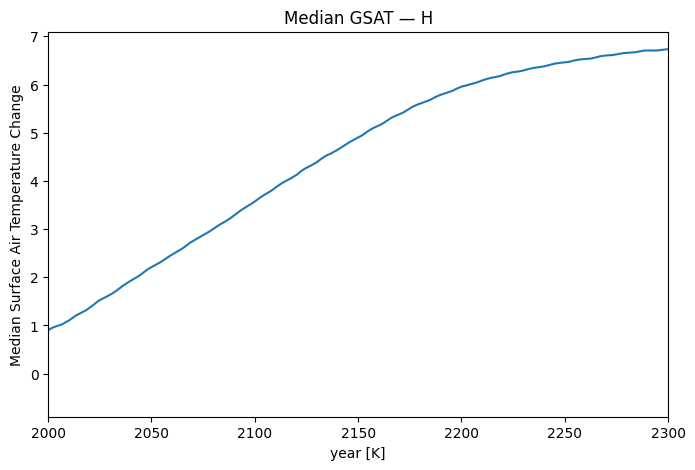

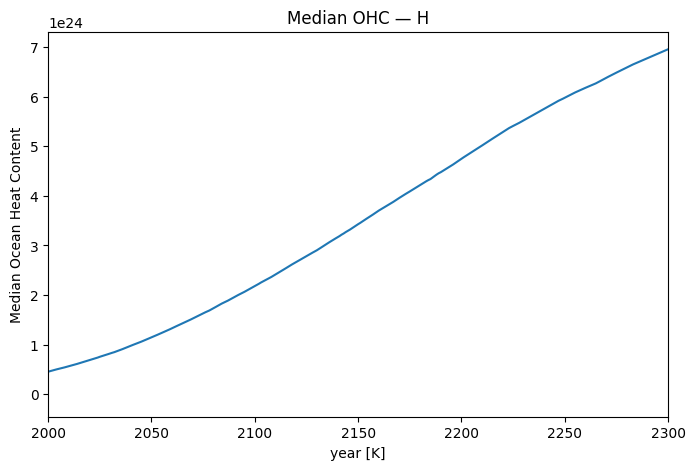

In [4]:
gsat_median.plot(
    x="year",
    figsize=(8, 5)
)
plt.xlim(2000, 2300)
plt.ylabel("Median Surface Air Temperature Change")
plt.title("Median GSAT — H")
plt.show()

ohc_median.plot(
    x="year",
    figsize=(8, 5)
)
plt.xlim(2000, 2300)
plt.ylabel("Median Ocean Heat Content")
plt.title("Median OHC — H")
plt.show()

### <font color = green> Import the <u>old</u> data.

In [5]:
old_datanc_gsat=xr.open_dataset("../2604_src/_data/cr8ed_fair_ip/src.H_ssp370_gsat.nc")
old_datanc_ohc=xr.open_dataset("../2604_src/_data/cr8ed_fair_ip/src.H_ssp370_ohc.nc")

In [6]:
old_datanc_gsat

<xarray.Dataset> Size: 13MB
Dimensions:              (samples: 2237, years: 751, locations: 1)
Coordinates:
  * samples              (samples) int64 18kB 0 1 2 3 4 ... 2233 2234 2235 2236
  * years                (years) int64 6kB 1750 1751 1752 ... 2498 2499 2500
  * locations            (locations) int64 8B -1
Data variables:
    surface_temperature  (samples, years, locations) float64 13MB ...
Attributes:
    Scenario:  ssp370
    SRC:       H

In [7]:
old_datanc_ohc

<xarray.Dataset> Size: 13MB
Dimensions:             (samples: 2237, years: 751, locations: 1)
Coordinates:
  * samples             (samples) int64 18kB 0 1 2 3 4 ... 2233 2234 2235 2236
  * years               (years) int64 6kB 1750 1751 1752 1753 ... 2498 2499 2500
  * locations           (locations) int64 8B -1
Data variables:
    ocean_heat_content  (samples, years, locations) float64 13MB ...
Attributes:
    Scenario:  ssp370
    SRC:       H

In [8]:
old_gsat_median = (
    old_datanc_gsat["surface_temperature"]
    .median(dim="samples")
)

old_ohc_median = (
    old_datanc_ohc["ocean_heat_content"]
    .median(dim="samples")
)

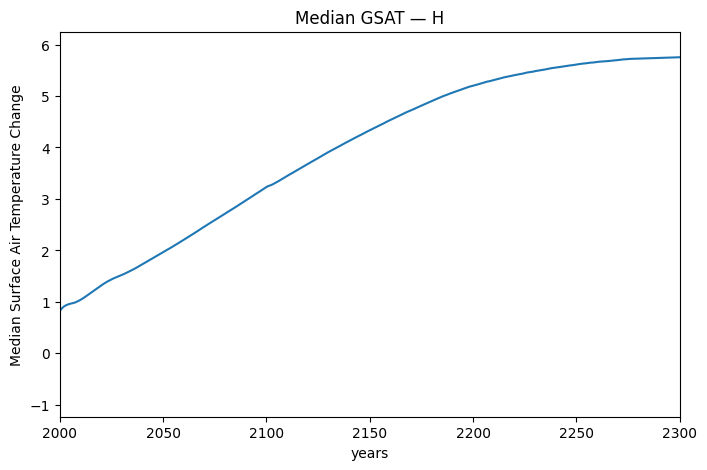

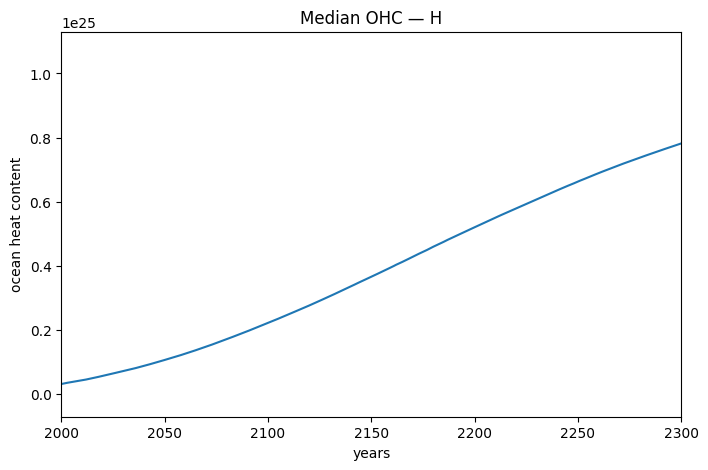

In [9]:
old_gsat_median.plot(
    x="years",
    figsize=(8, 5)
)

plt.xlim(2000, 2300)
plt.ylabel("Median Surface Air Temperature Change")
plt.title("Median GSAT — H")
plt.show()

#-------------------
old_ohc_median.plot(
    x="years",
    figsize=(8, 5)
)

plt.xlim(2000, 2300)
plt.ylabel("ocean heat content")
plt.title("Median OHC — H")
plt.show()

### Combined Plot

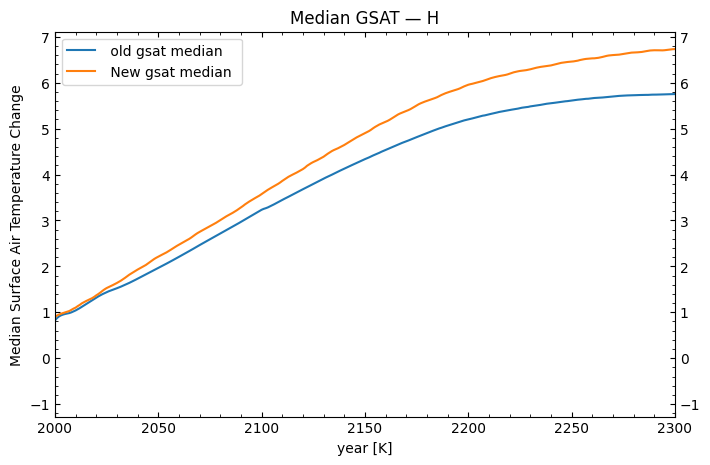

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

old_gsat_median.plot(
    x="years",
    ax=ax,
    label=" old gsat median "

)
gsat_median.plot(
    x="year",
    ax=ax,
    label=" New gsat median " 
)

# Major + minor ticks on all sides
ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True
)
ax.tick_params(
    axis="y",
    which="both",
    right=True,
    labelright=True
)

# Automatically add minor ticks
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())


ax.legend(loc="upper left")
plt.xlim(2000, 2300)
plt.ylabel("Median Surface Air Temperature Change")
plt.title("Median GSAT — H")
plt.show()

In [11]:
print("Old GSAT median at 2100:", old_gsat_median.sel(years=2100).item())
print("New GSAT median at 2100:", gsat_median.sel(year=2100).item())
print("Old GSAT median at 2300:", old_gsat_median.sel(years=2300).item())
print("New GSAT median at 2300:", gsat_median.sel(year=2300).item())

Old GSAT median at 2100: 3.2316642237640547
New GSAT median at 2100: 3.5723716578765004
Old GSAT median at 2300: 5.754924677283872
New GSAT median at 2300: 6.7325502988044645


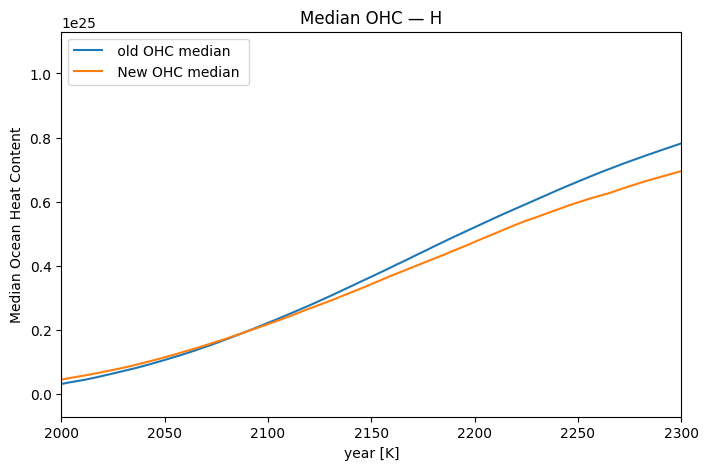

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

old_ohc_median.plot(
    x="years",
    ax=ax,
    label=" old OHC median "

)
ohc_median.plot(
    x="year",
    ax=ax,
    label=" New OHC median " 
)
ax.legend(loc="upper left")
plt.xlim(2000, 2300)
plt.ylabel("Median Ocean Heat Content")
plt.title("Median OHC — H")
plt.show()

---

### <font color = red> Convert to *nc data

In [14]:
# datanc=xr.open_dataset("_data/006_for-ipcc-cities-slr-emulators.nc")
datanc=xr.open_dataset("_data/007_for-ipcc-cities-slr-emulators.nc")


# Change the scenario labels. 
label_to_src = {
    "H": "H",
    "H to L": "HL",
    "M": "M",
    "M to L": "ML",
    "L": "L",
    "VL": "VL",
    "L to N": "LN",
}

# OLD SRC -> scenario mapping
group_scenarios = {
    "H":  "ssp370",
    "HL": "ssp585",
    "M":  "ssp245",
    "ML": "ssp245",
    "L":  "ssp245",
    "VL": "ssp126",
    "LN": "ssp245",
}

date_str = datetime.now().strftime("%Y%m%d")
output_dir = f"_data/cr8ed_fair_ip_{date_str}/"
os.makedirs(output_dir, exist_ok=True)


data_created_time = datetime.now().isoformat()

# Loop over plotting labels
for plotting_label, group in label_to_src.items():

    scenario = group_scenarios[group]

    print(
        f"\nProcessing plotting_label={plotting_label} "
        f"-> SRC={group} | scenario={scenario}")

    # Make sure requested label exists
    if plotting_label not in datanc["plotting_label"].values:
        print(f"Skipping {plotting_label}: not found in plotting_label")
        continue

    # --------------------------------------------------------
    # Surface Air Temperature
    # --------------------------------------------------------
    temp_da = (
        datanc["Surface Air Temperature Change"]
        .sel(plotting_label=plotting_label, drop=True)
        .rename({
            "run_id": "samples",
            "year": "years",
        })
        .rename("surface_temperature")
        .astype("float64")
    )

    # Variable metadata
    temp_da.attrs["units"] = "K"

    # Add locations dimension to match old GSAT file
    temp_ds = (temp_da.to_dataset().expand_dims(locations=[-1]).transpose("samples", "years", "locations"))

    # Global metadata
    temp_ds.attrs.update({
        "Scenario": scenario,
        "SRC": group,
        "Source Data File": "007_for-ipcc-cities-slr-emulators.nc",
        "Note": "data formatted by Praveen Kumar",
        "Created": data_created_time,
    })

    # Write the GSAT nc file
    temp_file = os.path.join(output_dir,f"src.{group}_{scenario}_gsat.nc")
    temp_ds.to_netcdf(temp_file,engine="h5netcdf")
    print(f"Saved {temp_file}")


    # --------------------------------------------------------
    # Ocean Heat Content 
    # --------------------------------------------------------
    ohc_da = (
        datanc["Heat Content"]
        .sel(
            plotting_label=plotting_label,
            component="Ocean",
            unit="ZJ",
            drop=True,
        )
        * np.float64(1e21)
    )
    # Data has been converted from ZJ --> J
    ohc_da.attrs["units"] = "J"

    
    ohc_da = (
        ohc_da
        .rename({
            "run_id": "samples",
            "year": "years",
        })
        .rename("ocean_heat_content")
        .astype("float64")
    )

    # Add locations dimension exactly like old output
    ohc_ds = (ohc_da.to_dataset().expand_dims(locations=[-1]).transpose("samples", "years", "locations"))

    ohc_ds.attrs.update({
        "Scenario": scenario,
        "SRC": group,
        "Source Data File": "007_for-ipcc-cities-slr-emulators.nc",
        "Note": "data formatted by Praveen Kumar",
        "Created": data_created_time,
    })

    # Write the OHC nc file
    ohc_file = os.path.join(output_dir,f"src.{group}_{scenario}_ohc.nc")
    ohc_ds.to_netcdf(ohc_file,engine="h5netcdf")
    print(f"Saved {ohc_file}")


    # --------------------------------------------------------
    # Create and Write climate file
    # --------------------------------------------------------
    climate_ds = (xr.merge([temp_ds,ohc_ds,]).squeeze("locations", drop=True).transpose("years", "samples"))

    climate_ds.attrs.update({
        "Scenario": scenario,
        "SRC": group,
        "Source Data File": "007_for-ipcc-cities-slr-emulators.nc",
        "Note": "data formatted by Praveen Kumar",
        "Created": data_created_time,
    })
    
    # Write the climate nc file
    climate_file = os.path.join(output_dir,f"src.{group}_{scenario}_climate.nc")
    climate_ds.to_netcdf(climate_file,engine="h5netcdf",group=scenario,mode="w",)
    # add year to the root level of climate file. 
    years_ds = xr.Dataset({"year": ("years",climate_ds["years"].values)})
    years_ds.to_netcdf(climate_file,engine="h5netcdf",mode="a",)
    
    print(climate_ds)
    print(f"Saved {climate_file}")

datanc.close()


Processing plotting_label=H -> SRC=H | scenario=ssp370
Saved _data/cr8ed_fair_ip_20260930/src.H_ssp370_gsat.nc
Saved _data/cr8ed_fair_ip_20260930/src.H_ssp370_ohc.nc
<xarray.Dataset> Size: 5MB
Dimensions:              (samples: 600, years: 551)
Coordinates:
  * samples              (samples) int64 5kB 0 1 2 3 4 5 ... 595 596 597 598 599
  * years                (years) int64 4kB 1750 1751 1752 ... 2298 2299 2300
Data variables:
    surface_temperature  (years, samples) float64 3MB 0.0 0.0 ... 8.029 6.676
    ocean_heat_content   (years, samples) float64 3MB 0.0 0.0 ... 1.111e+25
Attributes:
    Scenario:          ssp370
    SRC:               H
    Source Data File:  007_for-ipcc-cities-slr-emulators.nc
    Note:              data formatted by Praveen Kumar
    Created:           2026-09-30T06:26:51.528307
Saved _data/cr8ed_fair_ip_20260930/src.H_ssp370_climate.nc

Processing plotting_label=H to L -> SRC=HL | scenario=ssp585
Saved _data/cr8ed_fair_ip_20260930/src.HL_ssp585_gsat.nc
Sav

---

---

Before proceeding, please request `fair_scenarios.h5` data from Chris Smith(smithc@iiasa.ac.at)

In [ ]:
data_path="_data/fair_scenarios.h5" 

with h5py.File(data_path, "r") as f:
    print("Top-level keys:", list(f.keys()))

Top-level keys: ['H', 'HL', 'L', 'LN', 'M', 'ML', 'VL']


In [3]:
groups = ["H", "HL", "L", "LN", "M", "ML", "VL"]

opened = {}
for g in groups:
    try:
        ds = xr.open_dataset(
            data_path,
            engine="h5netcdf",
            group=f"/{g}",
            phony_dims="access",   
        )
        opened[g] = ds
        print(f"\n--- {g} ---")
        print(ds)
    except Exception as e:
        print(f"\n--- {g} FAILED ---")
        print(e)


--- H ---
<xarray.Dataset> Size: 54MB
Dimensions:                              (phony_dim_0: 751, phony_dim_1: 2237)
Dimensions without coordinates: phony_dim_0, phony_dim_1
Data variables:
    aerosol_effective_radiative_forcing  (phony_dim_0, phony_dim_1) float64 13MB ...
    effective_radiative_forcing          (phony_dim_0, phony_dim_1) float64 13MB ...
    ocean_heat_content                   (phony_dim_0, phony_dim_1) float64 13MB ...
    temperature                          (phony_dim_0, phony_dim_1) float64 13MB ...

--- HL ---
<xarray.Dataset> Size: 54MB
Dimensions:                              (phony_dim_0: 751, phony_dim_1: 2237)
Dimensions without coordinates: phony_dim_0, phony_dim_1
Data variables:
    aerosol_effective_radiative_forcing  (phony_dim_0, phony_dim_1) float64 13MB ...
    effective_radiative_forcing          (phony_dim_0, phony_dim_1) float64 13MB ...
    ocean_heat_content                   (phony_dim_0, phony_dim_1) float64 13MB ...
    temperature       

### Extract to .nc

In [4]:
# # group -> scenario mapping
# group_scenarios = {
#     "H" : "ssp370",
#     "HL": "ssp585",
#     "M" : "ssp245",
#     "ML": "ssp245",
#     "L" :  "ssp245",
#     "VL": "ssp126",
#     "LN": "ssp245",
# }

# output_dir = "_data/cr8ed_fair_ip/"
# os.makedirs(output_dir, exist_ok=True)

# for group, scenario in group_scenarios.items():
#     # open one HDF5 group
#     ds = xr.open_dataset(
#         data_path,
#         engine="h5netcdf",
#         group=f"/{group}",
#         phony_dims="access",
#     )

#     print(f"\nProcessing SRC: {group} | scenario: {scenario}")
#     print(ds)

#     # infer dimensions for this group
#     dim0, dim1 = list(ds.dims)
#     n_years = ds.sizes[dim0]
#     n_samples = ds.sizes[dim1]

#     years = np.arange(1750, 1750 + n_years)
#     samples = np.arange(n_samples)

#     # ---------------------------
#     # 1) ocean_heat_content
#     # ---------------------------
#     ohc_ds = (
#         ds[["ocean_heat_content"]]
#         .rename_dims({dim0: "years", dim1: "samples"})
#         .assign_coords(years=years, samples=samples)
#         .expand_dims("locations")
#         .assign_coords(locations=[-1])
#         .transpose("samples", "years", "locations")
#         .astype("float64")
#         .assign_attrs(Scenario=scenario, SRC=group)
#     )

#     ohc_file = os.path.join(output_dir, f"src.{group}_{scenario}_ohc.nc")
#     ohc_ds.to_netcdf(ohc_file, engine="h5netcdf")
#     print(f"Saved {ohc_file}")

#     # ---------------------------
#     # 2) surface_temperature
#     # ---------------------------
#     temp_ds = (
#         ds[["temperature"]]
#         .rename_dims({dim0: "years", dim1: "samples"})
#         .rename_vars({"temperature": "surface_temperature"})
#         .assign_coords(years=years, samples=samples)
#         .expand_dims("locations")
#         .assign_coords(locations=[-1])
#         .transpose("samples", "years", "locations")
#         .astype("float64")
#         .assign_attrs(Scenario=scenario, SRC=group)
#     )

#     temp_file = os.path.join(output_dir, f"src.{group}_{scenario}_gsat.nc")
#     temp_ds.to_netcdf(temp_file, engine="h5netcdf")
#     print(f"Saved {temp_file}")

#     ds.close()

---

In [5]:
# years = temp_ds.years.values.flatten()
# climate_ds = xr.merge([temp_ds, ohc_ds]).squeeze("locations",drop=True).transpose("years", "samples")
# climate_file = os.path.join(output_dir, f"src.{group}_{scenario}_climate.nc")
# climate_ds.to_netcdf(climate_file, engine="h5netcdf", group=scenario, mode="w")
# yearsds = xr.Dataset({"year": years})
# yearsds.to_netcdf(climate_file, engine = 'h5netcdf', mode='a')

# print(climate_ds)
# print(f"Saved {climate_file}")

In [6]:
# group -> scenario mapping
group_scenarios = {
    "H" : "ssp370",
    "HL": "ssp585",
    "M" : "ssp245",
    "ML": "ssp245",
    "L" : "ssp245",
    "VL": "ssp126",
    "LN": "ssp245",
}

output_dir = "_data/cr8ed_fair_ip/"
os.makedirs(output_dir, exist_ok=True)

for group, scenario in group_scenarios.items():
    # open one HDF5 group
    ds = xr.open_dataset(
        data_path,
        engine="h5netcdf",
        group=f"/{group}",
        phony_dims="access",
    )

    print(f"\nProcessing SRC: {group} | scenario: {scenario}")
    print(ds)

    # infer dimensions for this group
    dim0, dim1 = list(ds.dims)
    n_years = ds.sizes[dim0]
    n_samples = ds.sizes[dim1]

    years = np.arange(1750, 1750 + n_years)
    samples = np.arange(n_samples)

    # ---------------------------
    # 1) ocean_heat_content
    # ---------------------------
    ohc_ds = (
        ds[["ocean_heat_content"]]
        .rename_dims({dim0: "years", dim1: "samples"})
        .assign_coords(years=years, samples=samples)
        .expand_dims("locations")
        .assign_coords(locations=[-1])
        .transpose("samples", "years", "locations")
        .astype("float64")
        .assign_attrs(Scenario=scenario, SRC=group)
    )

    ohc_file = os.path.join(output_dir, f"src.{group}_{scenario}_ohc.nc")
    ohc_ds.to_netcdf(ohc_file, engine="h5netcdf")
    print(f"Saved {ohc_file}")

    # ---------------------------
    # 2) surface_temperature
    # ---------------------------
    temp_ds = (
        ds[["temperature"]]
        .rename_dims({dim0: "years", dim1: "samples"})
        .rename_vars({"temperature": "surface_temperature"})
        .assign_coords(years=years, samples=samples)
        .expand_dims("locations")
        .assign_coords(locations=[-1])
        .transpose("samples", "years", "locations")
        .astype("float64")
        .assign_attrs(Scenario=scenario, SRC=group)
    )

    temp_file = os.path.join(output_dir, f"src.{group}_{scenario}_gsat.nc")
    temp_ds.to_netcdf(temp_file, engine="h5netcdf")
    print(f"Saved {temp_file}")

    # ---------------------------
    # 3) combined climate file
    # ---------------------------
    climate_ds = (
        xr.merge([temp_ds, ohc_ds])
        .squeeze("locations", drop=True)
        .transpose("years", "samples")
        .assign_attrs(Scenario=scenario, SRC=group)
    )

    climate_file = os.path.join(output_dir, f"src.{group}_{scenario}_climate.nc")
    climate_ds.to_netcdf(climate_file, engine="h5netcdf", group=scenario, mode="w")

    years_ds = xr.Dataset({"year": ("years", years)})
    years_ds.to_netcdf(climate_file, engine="h5netcdf", mode="a")

    print(climate_ds)
    print(f"Saved {climate_file}")

    ds.close()


Processing SRC: H | scenario: ssp370
<xarray.Dataset> Size: 54MB
Dimensions:                              (phony_dim_0: 751, phony_dim_1: 2237)
Dimensions without coordinates: phony_dim_0, phony_dim_1
Data variables:
    aerosol_effective_radiative_forcing  (phony_dim_0, phony_dim_1) float64 13MB ...
    effective_radiative_forcing          (phony_dim_0, phony_dim_1) float64 13MB ...
    ocean_heat_content                   (phony_dim_0, phony_dim_1) float64 13MB ...
    temperature                          (phony_dim_0, phony_dim_1) float64 13MB ...
Saved _data/cr8ed_fair_ip/src.H_ssp370_ohc.nc
Saved _data/cr8ed_fair_ip/src.H_ssp370_gsat.nc
<xarray.Dataset> Size: 27MB
Dimensions:              (samples: 2237, years: 751)
Coordinates:
  * samples              (samples) int64 18kB 0 1 2 3 4 ... 2233 2234 2235 2236
  * years                (years) int64 6kB 1750 1751 1752 ... 2498 2499 2500
Data variables:
    surface_temperature  (years, samples) float64 13MB 0.02783 0.02749 ... 5.477
 